# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [26]:
import numpy as np
import pandas as pd

def compute_local_zscore(transcripts, extracellular_transcripts, n_bins=40, verbose=False):
    """
    Compute local z-score for both intracellular and extracellular transcripts
    using shared spatial bin statistics.
    """
    # Combine data and tag source
    combined = pd.concat([
        transcripts.assign(source='intra'),
        extracellular_transcripts.assign(source='extra')
    ], ignore_index=True)

    # Assign spatial bins
    combined['x_bin'] = pd.qcut(combined['x'], q=n_bins, duplicates='drop')
    combined['y_bin'] = pd.qcut(combined['y'], q=n_bins, duplicates='drop')

    if verbose:
        print("Assigned x_bin and y_bin:")
        print(combined[['x_bin', 'y_bin']].head())

    # Drop rows with NaN bins (can happen if x or y is constant or near-constant)
    valid_combined = combined.dropna(subset=['x_bin', 'y_bin'])

    # Compute local mean and std
    grouped = valid_combined.groupby(['x_bin', 'y_bin'])['z'].agg(['mean', 'std']).reset_index()
    grouped.columns = ['x_bin', 'y_bin', 'local_mean', 'local_std']

    if verbose:
        print("Computed local stats:")
        print(grouped.head())

    # Merge with all (including rows dropped above)
    combined = combined.merge(grouped, on=['x_bin', 'y_bin'], how='left')

    # Compute z_local only where stats are available
    combined['z_local'] = (combined['z'] - combined['local_mean']) / combined['local_std']

    # Split and return
    transcripts = combined[combined['source'] == 'intra'].drop(columns='source')
    extracellular_transcripts = combined[combined['source'] == 'extra'].drop(columns='source')

    return transcripts, extracellular_transcripts


import numpy as np
import matplotlib.pyplot as plt

def plot_normalized_z_distributions(transcripts, extracellular_transcripts, z_col='z_local', bins=200):
    """
    Plot normalized histograms of z-local values for intracellular and extracellular transcripts.

    Parameters
    ----------
    transcripts : pd.DataFrame
        DataFrame containing intracellular transcript data with a column for z-scores.
    extracellular_transcripts : pd.DataFrame
        DataFrame containing extracellular transcript data with a column for z-scores.
    z_col : str
        Column name in both dataframes containing the z-score values (default='z_local').
    bins : int
        Number of histogram bins (default=200).
    """
    # Define common bin edges
    z_min = min(transcripts[z_col].min(), extracellular_transcripts[z_col].min())
    z_max = max(transcripts[z_col].max(), extracellular_transcripts[z_col].max())
    bin_edges = np.linspace(z_min, z_max, bins)

    # Compute histograms
    hist_intra, _ = np.histogram(transcripts[z_col], bins=bin_edges)
    hist_extra, _ = np.histogram(extracellular_transcripts[z_col], bins=bin_edges)

    # Normalize histograms
    hist_intra = hist_intra / hist_intra.sum()
    hist_extra = hist_extra / hist_extra.sum()

    # Bin centers for plotting
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Plot
    plt.figure(figsize=(6, 4))
    plt.plot(bin_centers, hist_intra, label='Intracellular transcripts (normalized)', color='blue')
    plt.plot(bin_centers, hist_extra, label='Extracellular transcripts (normalized)', color='red')
    plt.xlabel('Local z-score')
    plt.ylabel('Normalized density')
    plt.title('Normalized Distribution of Local Z-scores')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

import numpy as np
import matplotlib.pyplot as plt

def plot_z_coordinate_distributions(transcripts, extracellular_transcripts, z_col='z', bins=100):
    """
    Plot normalized histograms of raw z-coordinate values for intracellular and extracellular transcripts.

    Parameters
    ----------
    transcripts : pd.DataFrame
        DataFrame with intracellular transcript data containing a 'z' coordinate.
    extracellular_transcripts : pd.DataFrame
        DataFrame with extracellular transcript data containing a 'z' coordinate.
    z_col : str
        Column name for the z-coordinate values (default='z').
    bins : int
        Number of bins to use in the histogram (default=100).
    """
    # Compute common bin edges
    z_min = min(transcripts[z_col].min(), extracellular_transcripts[z_col].min())
    z_max = max(transcripts[z_col].max(), extracellular_transcripts[z_col].max())
    bin_edges = np.linspace(z_min, z_max, bins)

    # Compute histograms
    hist_intra, _ = np.histogram(transcripts[z_col], bins=bin_edges)
    hist_extra, _ = np.histogram(extracellular_transcripts[z_col], bins=bin_edges)

    # Normalize
    hist_intra = hist_intra / hist_intra.sum()
    hist_extra = hist_extra / hist_extra.sum()

    # Compute bin centers
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Plot
    plt.figure(figsize=(8, 5))
    plt.plot(bin_centers, hist_intra, label='Intracellular transcripts (normalized)', color='blue')
    plt.plot(bin_centers, hist_extra, label='Extracellular transcripts (normalized)', color='red')
    plt.xlabel('Z coordinate')
    plt.ylabel('Normalized density')
    plt.title('Normalized Z-distribution of Transcripts')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [28]:
# Read, within rois, all subfolders, and read data_processed.zarr, in a loop. this is samp

sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_hsskin_5k/data_processed.zarr")

## 
extracellular_transcripts=sdata['extracellular_transcripts'][['x','y','z','gene','extracellular']].compute()
transcripts=sdata['transcripts'][['x','y','z','gene','extracellular']].compute()
transcripts=transcripts[transcripts['extracellular']==False]
print(samp)
transcripts, extracellular_transcripts = compute_local_zscore(transcripts, extracellular_transcripts, n_bins=40, verbose=True)
plot_z_coordinate_distributions(transcripts, extracellular_transcripts)
plot_normalized_z_distributions(transcripts, extracellular_transcripts)


In [36]:
import os
import spatialdata as sd
import pandas as pd

def process_all_rois(base_dir, n_bins=40):
    """
    Loop over all ROI subfolders in a base directory, read `data_processed.zarr` files,
    extract transcript data, compute local z-scores, and plot z distributions.

    Parameters
    ----------
    base_dir : str
        Path to the base directory containing subfolders with `data_processed.zarr`.
    n_bins : int
        Number of spatial bins for local z-score normalization.
    """
    for folder in os.listdir(base_dir)[7:]:
        folder_path = os.path.join(base_dir, folder)
        zarr_path = os.path.join(folder_path, "data_processed.zarr")

        if not os.path.isdir(folder_path) or not os.path.exists(zarr_path):
            continue  # skip files or folders without the zarr

        print(f"\nProcessing: {folder}")
        
        # Read SpatialData object
        sdata = sd.read_zarr(zarr_path)

        # Extract transcript data
        extracellular_transcripts = sdata['extracellular_transcripts'][['x','y','z','gene','extracellular']].compute()
        transcripts = sdata['transcripts'][['x','y','z','gene','extracellular']].compute()
        transcripts = transcripts[transcripts['extracellular'] == False]

        # Compute local z-scores
        transcripts, extracellular_transcripts = compute_local_zscore(
            transcripts, extracellular_transcripts, n_bins=n_bins, verbose=False
        )

        # Plot raw and normalized z-coordinate distributions
        plot_normalized_z_coordinate_distributions(transcripts, extracellular_transcripts)
        plot_normalized_z_distributions(transcripts, extracellular_transcripts)



Processing: xenium_hsfemur


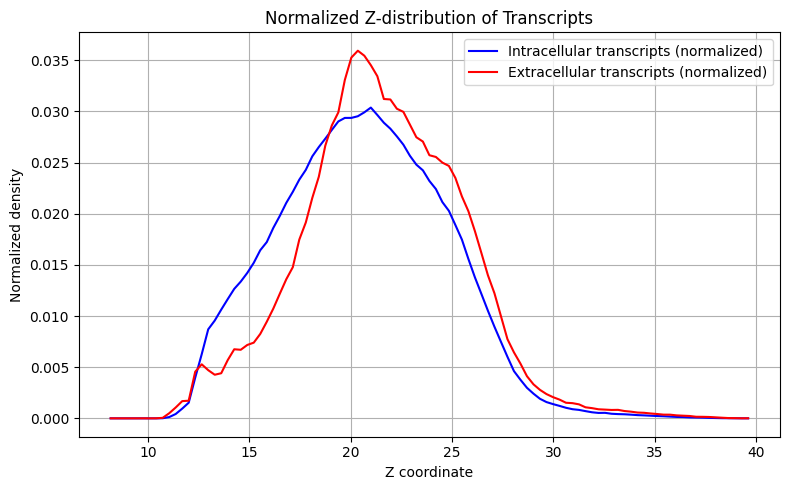

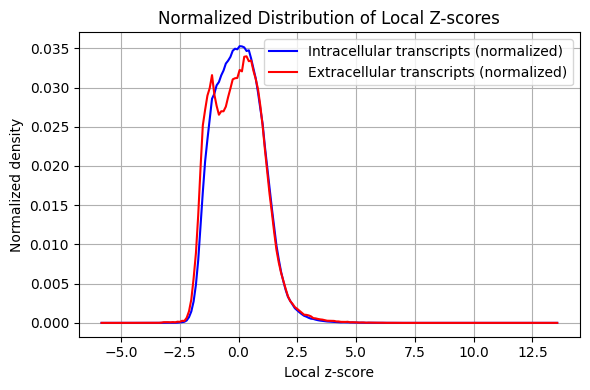


Processing: xenium_hsheart


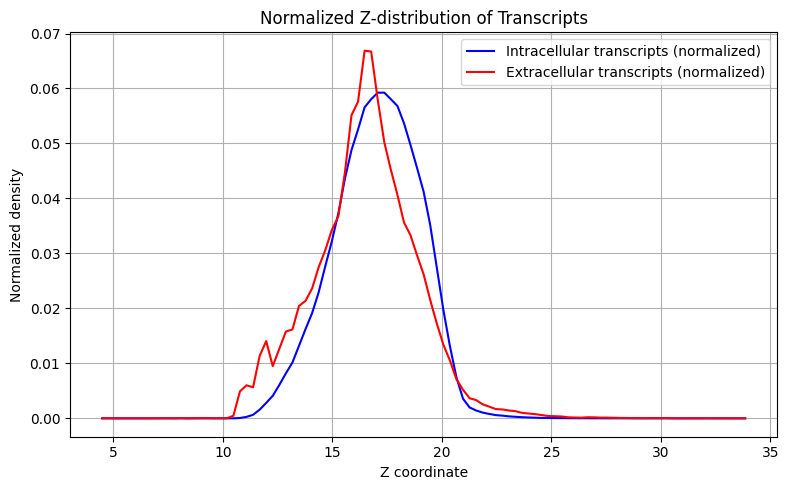

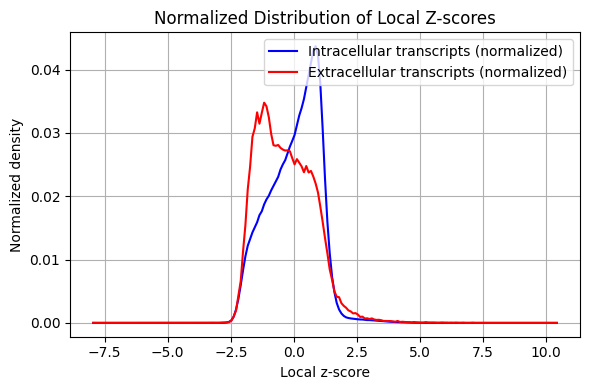


Processing: xenium_hsprostate


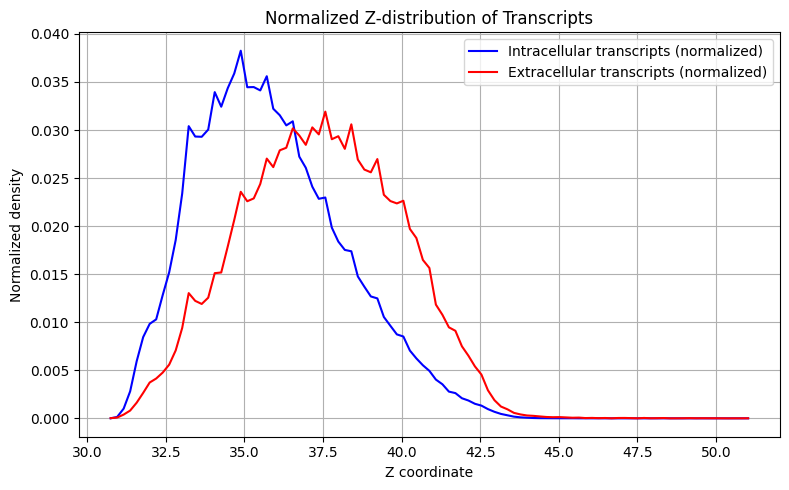

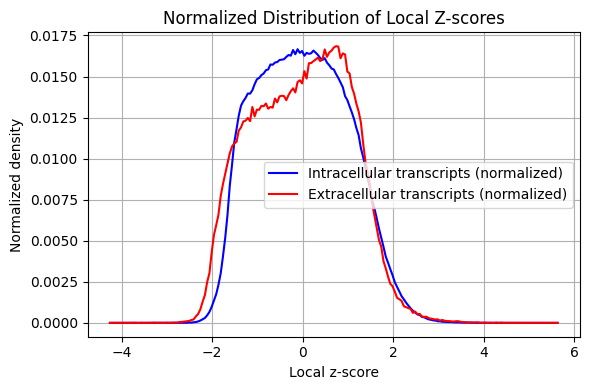


Processing: xenium_hsputamen


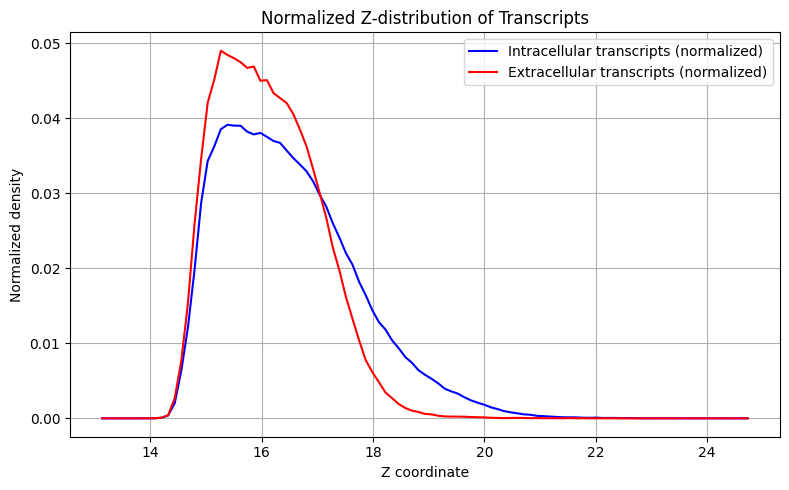

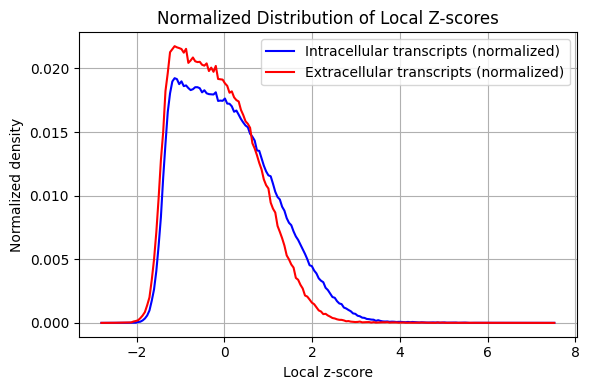


Processing: xenium_hsskin_5k


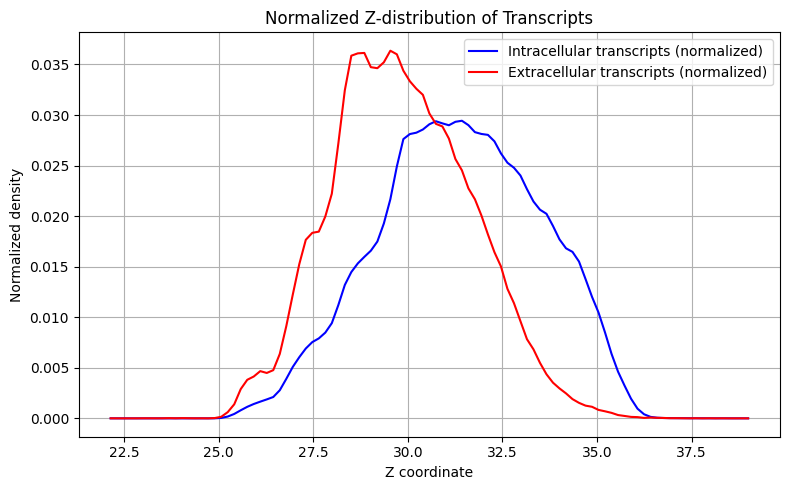

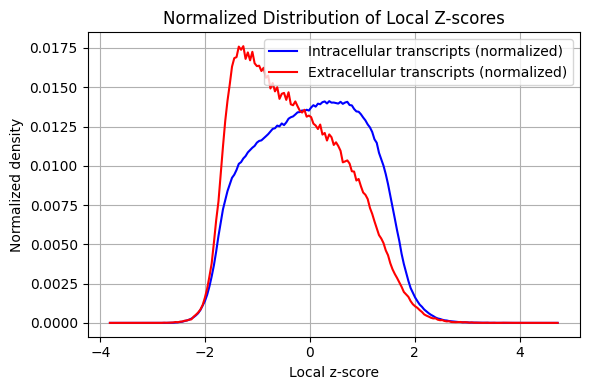


Processing: xenium_msbrain_300


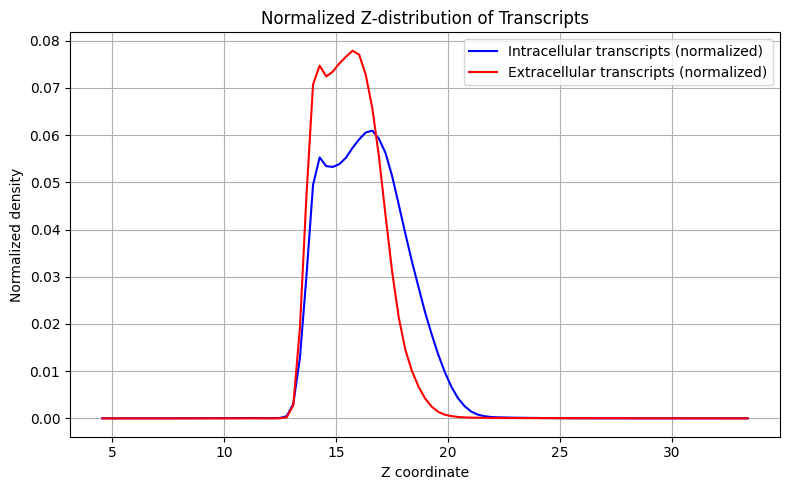

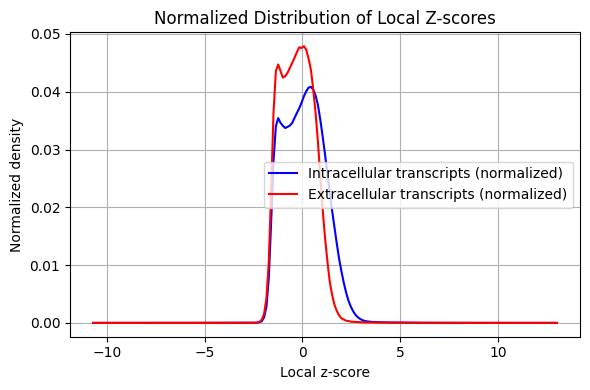


Processing: xenium_msbrain_5k


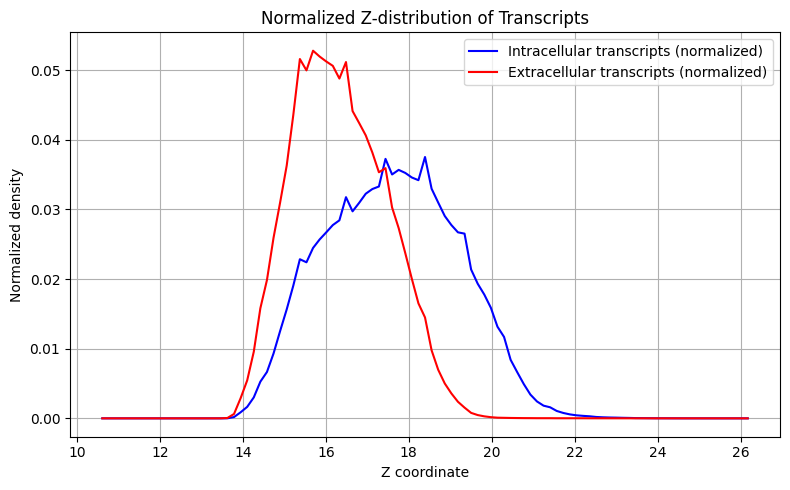

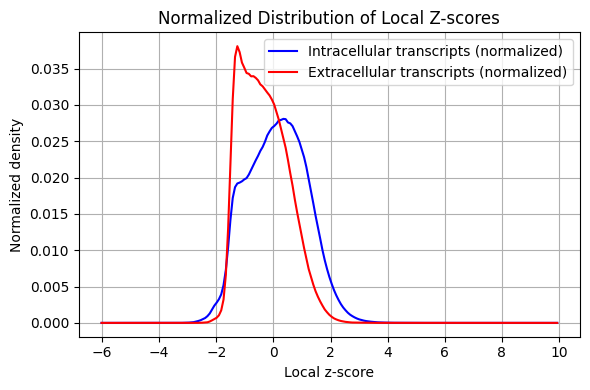


Processing: xenium_mscolon_5k


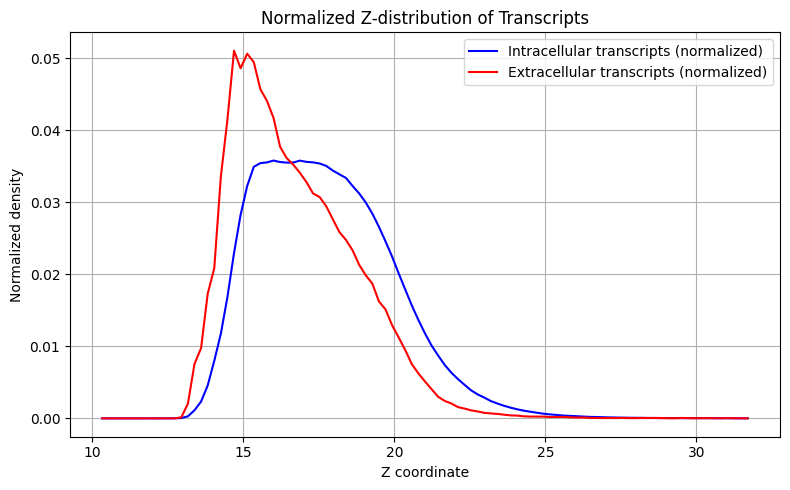

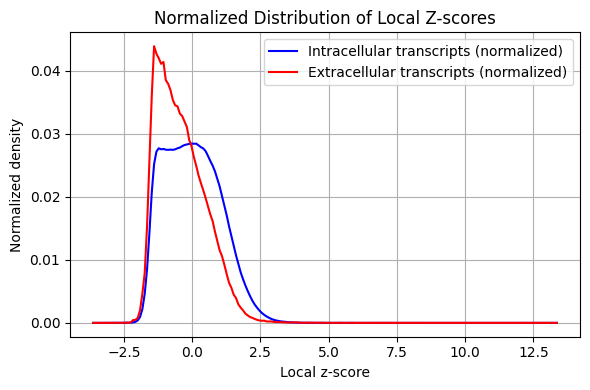

In [37]:
base_dir='/media/sergio/Meninges/troutpy/rois'
process_all_rois(base_dir, n_bins=40)